In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

DATA_PATH = Path("../data/processed/all_transactions.csv")

transactions = pd.read_csv(DATA_PATH)

transactions["timestamp"] = pd.to_datetime(
    transactions["timestamp"]
)

print("Dataset shape:", transactions.shape)
print("\nFraud distribution:")
print(transactions["is_fraud"].value_counts())

print("\nScenario distribution:")
print(transactions["fraud_scenario"].value_counts())


Dataset shape: (99975, 12)

Fraud distribution:
is_fraud
0    98476
1     1499
Name: count, dtype: int64

Scenario distribution:
fraud_scenario
NORMAL                98476
UNUSUAL_AMOUNT          300
RAPID_TRANSACTIONS      300
COORDINATED_FRAUD       300
MONEY_LAUNDERING        300
ACCOUNT_TAKEOVER        299
Name: count, dtype: int64


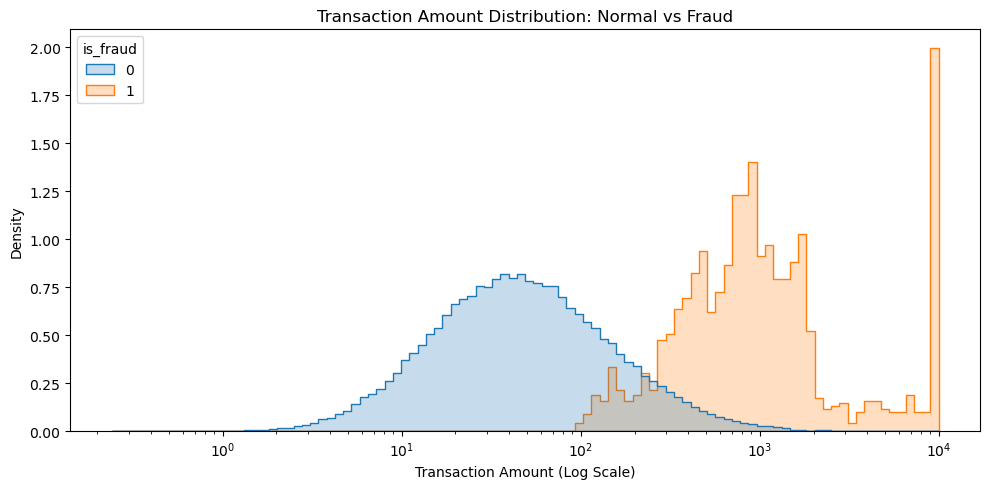

In [2]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=transactions,
    x="amount",
    hue="is_fraud",
    bins=100,
    log_scale=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Amount Distribution: Normal vs Fraud")
plt.xlabel("Transaction Amount (Log Scale)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


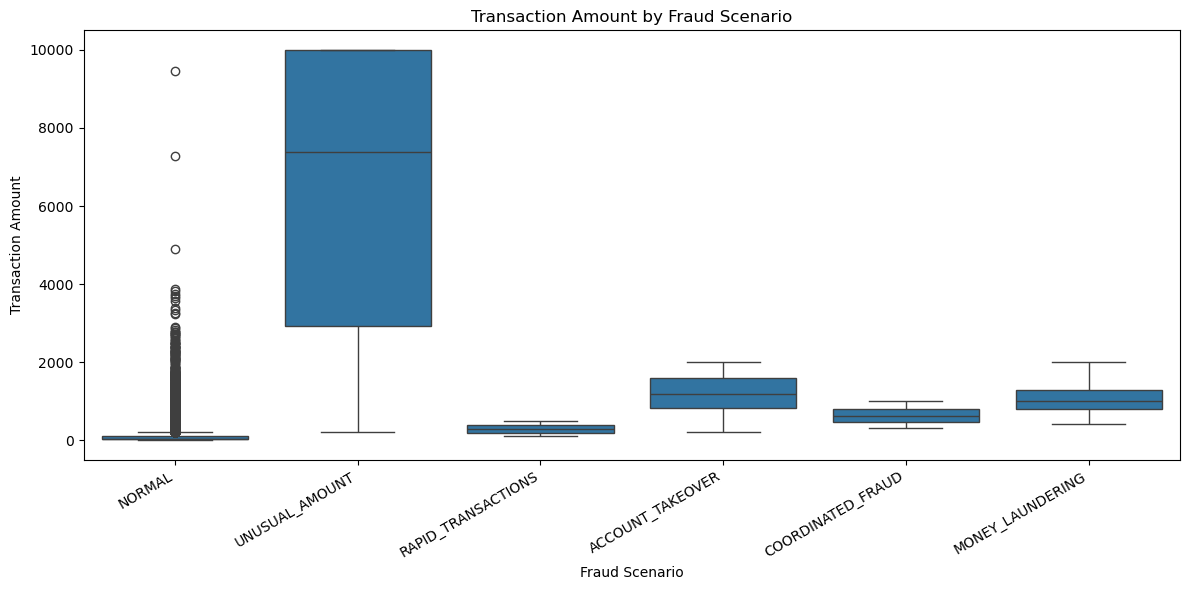

In [3]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=transactions,
    x="fraud_scenario",
    y="amount"
)

plt.title("Transaction Amount by Fraud Scenario")
plt.xlabel("Fraud Scenario")
plt.ylabel("Transaction Amount")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [4]:

transactions["hour"] = transactions["timestamp"].dt.hour
transactions["day"] = transactions["timestamp"].dt.day
transactions["date"] = transactions["timestamp"].dt.date

display(
    transactions[
        ["timestamp", "hour", "day", "date", "is_fraud"]
    ].head()
)


,timestamp,hour,day,date,is_fraud
0,2026-01-01 00:00:34.132897690,0,1,2026-01-01,0
1,2026-01-01 00:00:34.427735075,0,1,2026-01-01,0
2,2026-01-01 00:00:49.868826972,0,1,2026-01-01,0
3,2026-01-01 00:01:11.188848846,0,1,2026-01-01,0
4,2026-01-01 00:02:02.367877342,0,1,2026-01-01,0


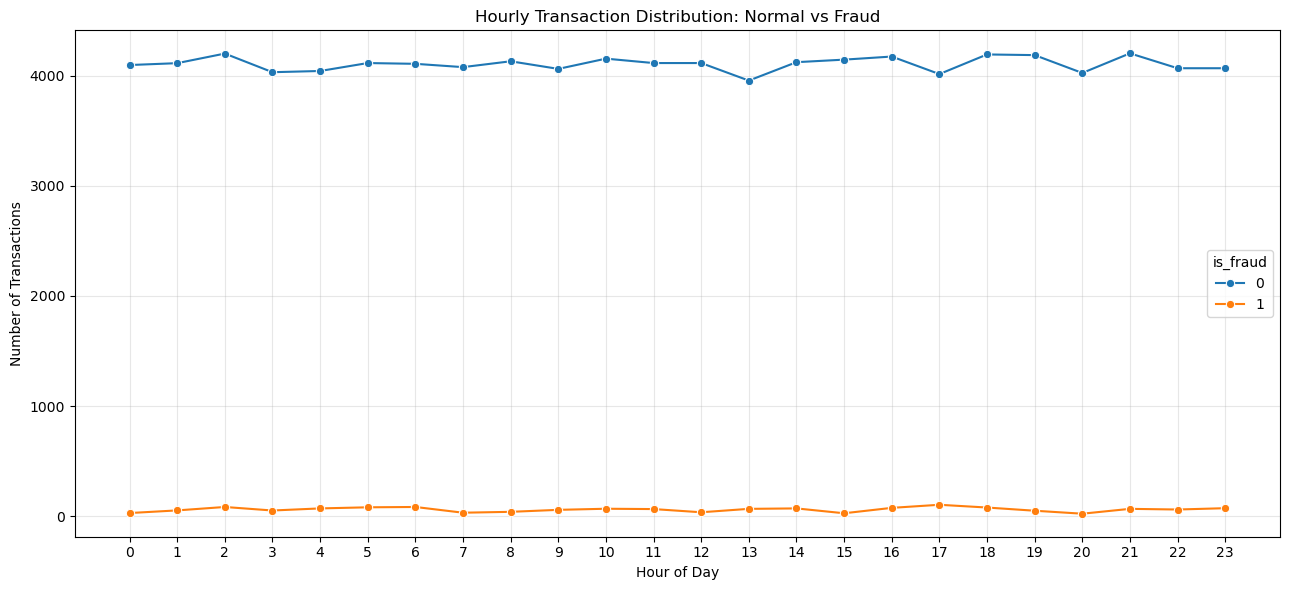

In [5]:

hourly_transactions = (
    transactions.groupby(["hour", "is_fraud"])
    .size()
    .reset_index(name="transaction_count")
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=hourly_transactions,
    x="hour",
    y="transaction_count",
    hue="is_fraud",
    marker="o"
)

plt.title("Hourly Transaction Distribution: Normal vs Fraud")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


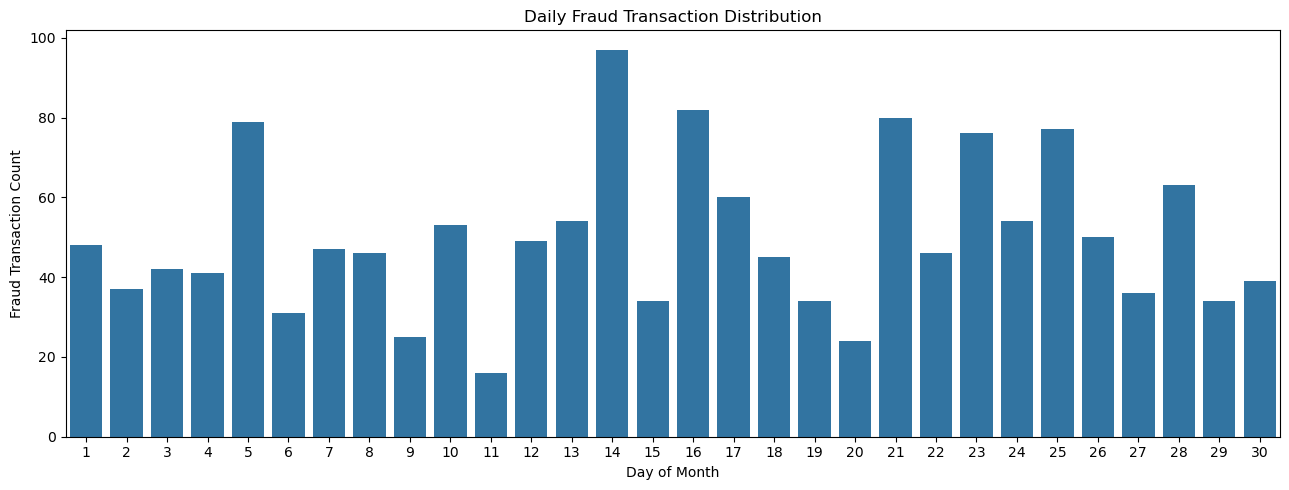

In [6]:

daily_fraud = (
    transactions[transactions["is_fraud"] == 1]
    .groupby("day")
    .size()
    .reset_index(name="fraud_count")
)

plt.figure(figsize=(13, 5))

sns.barplot(
    data=daily_fraud,
    x="day",
    y="fraud_count"
)

plt.title("Daily Fraud Transaction Distribution")
plt.xlabel("Day of Month")
plt.ylabel("Fraud Transaction Count")
plt.tight_layout()
plt.show()


,total_transactions,fraud_transactions,fraud_rate
hour,,,
0,4126,31,0.75
1,4167,55,1.32
2,4285,86,2.01
3,4084,54,1.32
4,4114,73,1.77
5,4196,83,1.98
6,4192,86,2.05
7,4110,34,0.83
8,4171,42,1.01


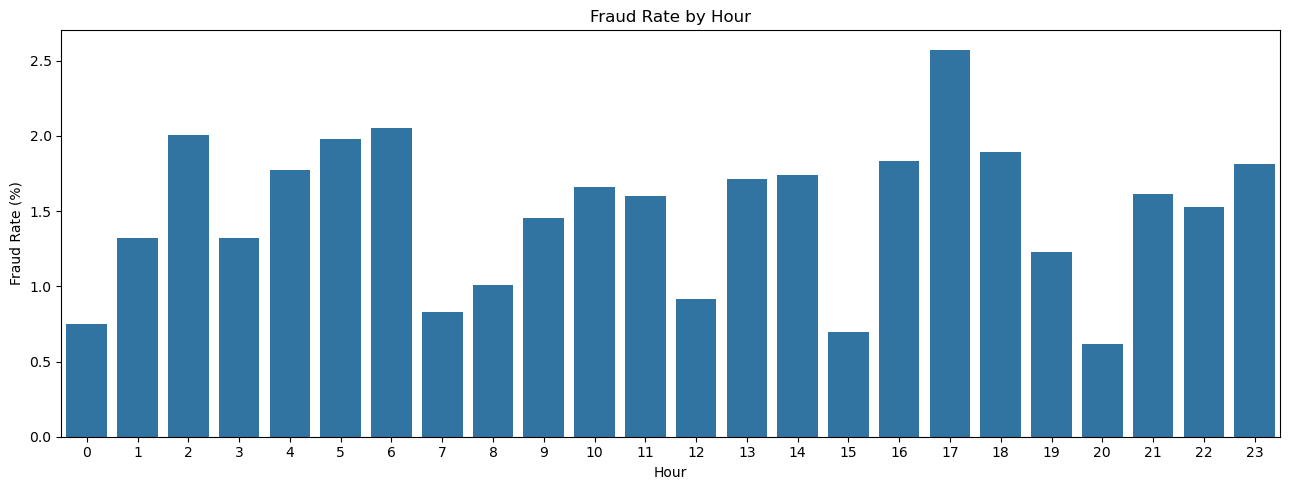

In [7]:

hourly_fraud_rate = (
    transactions.groupby("hour")
    .agg(
        total_transactions=("is_fraud", "count"),
        fraud_transactions=("is_fraud", "sum")
    )
)

hourly_fraud_rate["fraud_rate"] = (
    hourly_fraud_rate["fraud_transactions"]
    / hourly_fraud_rate["total_transactions"]
    * 100
)

display(hourly_fraud_rate.round(2))

plt.figure(figsize=(13, 5))

sns.barplot(
    x=hourly_fraud_rate.index,
    y=hourly_fraud_rate["fraud_rate"]
)

plt.title("Fraud Rate by Hour")
plt.xlabel("Hour")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(24))
plt.tight_layout()
plt.show()


In [8]:

account_features = (
    transactions.groupby("sender_id")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        avg_amount=("amount", "mean"),
        max_amount=("amount", "max"),
        std_amount=("amount", "std"),
        unique_receivers=("receiver_id", "nunique"),
        unique_devices=("device_id", "nunique"),
        unique_locations=("location", "nunique"),
        fraud_count=("is_fraud", "sum")
    )
    .reset_index()
)

account_features["is_fraud_account"] = (
    account_features["fraud_count"] > 0
).astype(int)

display(account_features.head())

print("Account-level dataset shape:", account_features.shape)


,sender_id,transaction_count,total_amount,avg_amount,max_amount,std_amount,unique_receivers,unique_devices,unique_locations,fraud_count,is_fraud_account
0,ACC_000001,12,2365.02,197.085000,772.78,255.563727,12,1,1,0,0
1,ACC_000002,8,541.81,67.726250,142.31,52.970451,8,1,1,0,0
2,ACC_000003,12,1089.24,90.770000,242.82,77.372104,12,1,1,0,0
3,ACC_000004,11,899.05,81.731818,376.32,111.079037,11,1,1,0,0
4,ACC_000005,3,42.58,14.193333,28.66,12.745153,3,1,1,0,0


Account-level dataset shape: (10000, 11)


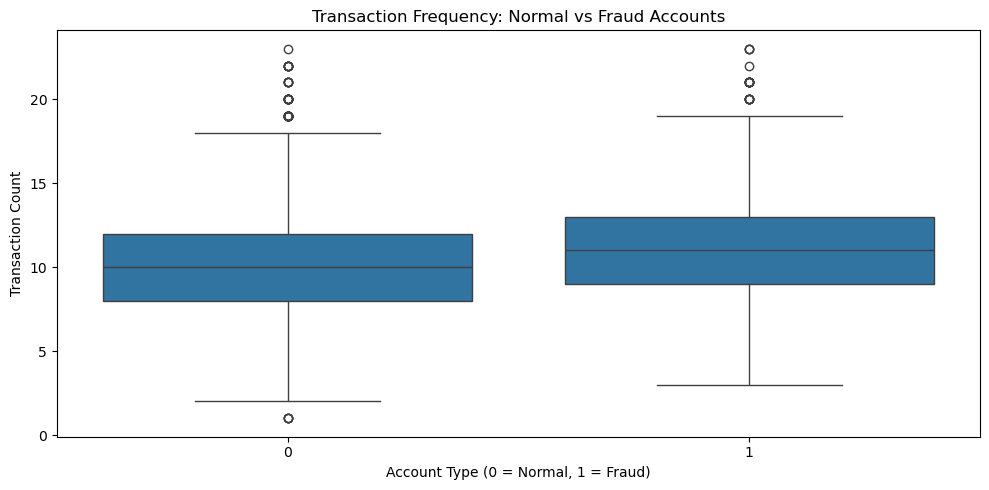

In [9]:

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=account_features,
    x="is_fraud_account",
    y="transaction_count"
)

plt.title("Transaction Frequency: Normal vs Fraud Accounts")
plt.xlabel("Account Type (0 = Normal, 1 = Fraud)")
plt.ylabel("Transaction Count")
plt.tight_layout()
plt.show()


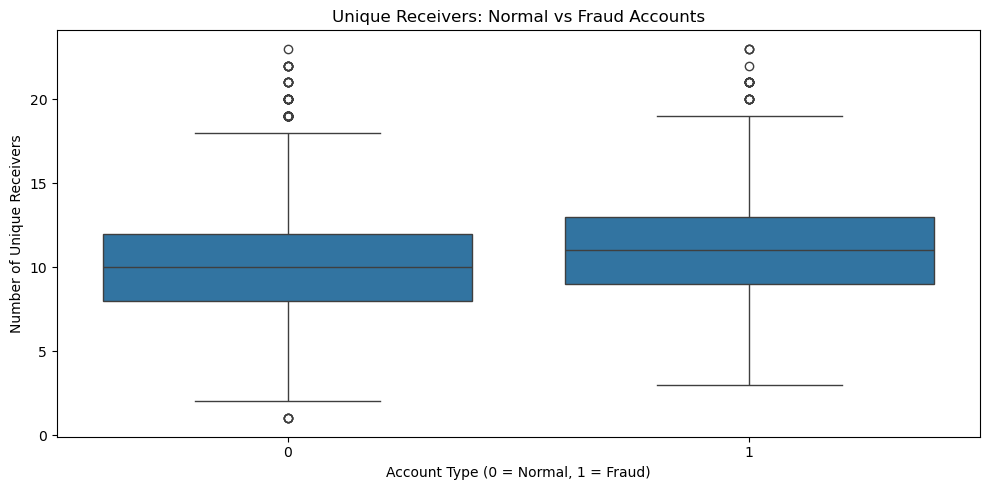

In [10]:

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=account_features,
    x="is_fraud_account",
    y="unique_receivers"
)

plt.title("Unique Receivers: Normal vs Fraud Accounts")
plt.xlabel("Account Type (0 = Normal, 1 = Fraud)")
plt.ylabel("Number of Unique Receivers")
plt.tight_layout()
plt.show()


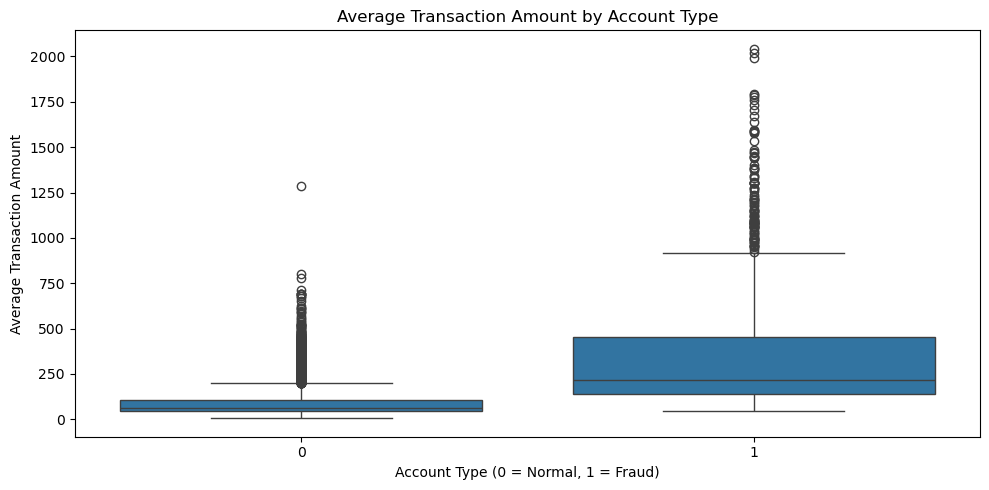

In [11]:

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=account_features,
    x="is_fraud_account",
    y="avg_amount"
)

plt.title("Average Transaction Amount by Account Type")
plt.xlabel("Account Type (0 = Normal, 1 = Fraud)")
plt.ylabel("Average Transaction Amount")
plt.tight_layout()
plt.show()
